[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch27_LabCh27_Autoencoders.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 27: Autoencoders** (Part VI: Imagining).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=27](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=27)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch27 - Autoencoders
## Copy the input through a narrow middle, and see what the network keeps

This lab goes with **Chapter 27** of *The Why Book of Deep Learning*.

An autoencoder is trained to output its own input. That sounds pointless until you make the middle of the
network narrow: 784 pixels must squeeze through 32 numbers and come back out. To succeed, the network has
to find out what matters about a digit and throw the rest away, and nobody gives it a single label.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Count the parameters of a dense autoencoder by hand, 209,968 of them | Step 3 |
| Train it with binary cross-entropy and read its reconstructions | Steps 4 and 5 |
| Compare it honestly with PCA at the same code size | Step 6 |
| Look at a 2-D latent space and find its holes | Steps 7 and 8 |
| Build a denoising autoencoder and test it on noisy digits | Step 9 |
| Predict the shape table of a convolutional autoencoder 28 → 14 → 7 → 14 → 28 | Step 10 |
| Use reconstruction error to flag digits the model never saw, and see where it fails | Steps 11 and 12 |
| Catch an over-wide autoencoder copying instead of learning | Step 13 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** a few minutes on a laptop CPU. To keep it short we train on **20,000** of the 60,000
> training digits, for only a handful of epochs. For a real run use all 60,000 and 20 to 50 epochs:
> the reconstructions get sharper, but none of the lessons change.

---
## Step 1 - Imports and one seed

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(27)
np.set_printoptions(precision=4, suppress=True)
T0 = time.time()
print("Keras:", keras.__version__)

Keras: 3.14.1


---
## Step 2 - Load MNIST, scale to [0, 1], flatten

The decoder will end with a **sigmoid**, which can only output numbers between 0 and 1. So the targets (the
input pixels themselves) must live in [0, 1] too: divide by 255.

> **Predict:** the shape of one flattened digit, and the largest pixel value after scaling.

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()
N_TRAIN = 20_000                                     # raise to 60_000 for a real run
x_train = x_train_full[:N_TRAIN].astype("float32") / 255.0
y_train = y_train_full[:N_TRAIN]
x_test = x_test.astype("float32") / 255.0

x_train_flat = x_train.reshape(-1, 784)
x_test_flat = x_test.reshape(-1, 784)
print("train:", x_train_flat.shape, " test:", x_test_flat.shape)
print("pixel range:", x_train_flat.min(), "to", x_train_flat.max())
print(f"share of pixels that are exactly 0: {np.mean(x_train_flat == 0):.1%}")

train: (20000, 784)  test: (10000, 784)
pixel range: 0.0 to 1.0
share of pixels that are exactly 0: 80.8%


### Why we see this

Each digit is a row of 784 numbers between 0 and 1. About four in five pixels are pure black background:
the first thing any autoencoder learns is "most of the picture is empty", which is why even a bad one
produces something digit-shaped.

---
## Step 3 - Count the parameters before you build

The dense autoencoder is **784 → 128 → 32 → 128 → 784**. Each `Dense` layer has (inputs + 1) × units
parameters: one weight per input per unit, plus one bias per unit.

> **Predict:** the four layer counts and the total. (Hint: the first and last layers are nearly mirror images,
> but not quite. Why?)

In [3]:
hand = {
    "enc_128": (784 + 1) * 128,
    "code_32": (128 + 1) * 32,
    "dec_128": (32 + 1) * 128,
    "out_784": (128 + 1) * 784,
}
for k, v in hand.items():
    print(f"{k:8s} {v:>8,}")
HAND_TOTAL = sum(hand.values())
print(f"{'total':8s} {HAND_TOTAL:>8,}")
print(f"compression: 784 / 32 = {784 / 32}")

def dense_autoencoder(code_size=32, hidden=128, name="dense_ae", code_act="relu"):
    inp = layers.Input(shape=(784,))
    h = layers.Dense(hidden, activation="relu", name="enc_128")(inp)
    code = layers.Dense(code_size, activation=code_act, name="code")(h)
    h = layers.Dense(hidden, activation="relu", name="dec_128")(code)
    out = layers.Dense(784, activation="sigmoid", name="out_784")(h)
    ae = keras.Model(inp, out, name=name)
    encoder = keras.Model(inp, code, name=name + "_encoder")
    return ae, encoder

ae, encoder = dense_autoencoder()
ae.summary()
assert ae.count_params() == HAND_TOTAL == 209_968
print("hand count matches Keras:", ae.count_params())

enc_128   100,480
code_32     4,128
dec_128     4,224
out_784   101,136
total     209,968
compression: 784 / 32 = 24.5


Model: "dense_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_128 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Dense)                    │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_128 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out_784 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

hand count matches Keras: 209968


### Why we see this

100,480 + 4,128 + 4,224 + 101,136 = **209,968**. The first layer has 784 × 128 weights and 128 biases;
the last has 128 × 784 weights but **784** biases, one per output pixel, so it is 656 parameters bigger.
96% of the parameters sit in the two outer layers that touch the pixels: the bottleneck itself is
cheap. Notice also that the encoder is a model of its own (`encoder`) that **shares** its layers with the
autoencoder: train one and the other is trained too.

---
## Step 4 - Train it to copy

The target is the input: `fit(x, x)`. The loss is **binary cross-entropy**, pixel by pixel: each output pixel
is read as "how likely is this pixel to be ink?". It suits pixels in [0, 1] that are mostly near 0 or 1.

> **Predict:** a model that outputs 0.5 everywhere has a BCE of ln 2 ≈ 0.693. Where will the first epoch end:
> near 0.69, near 0.3, or below 0.15?

In [4]:
ae.compile(optimizer="adam", loss="binary_crossentropy")
t = time.time()
hist = ae.fit(x_train_flat, x_train_flat, epochs=8, batch_size=128,
              validation_data=(x_test_flat, x_test_flat), verbose=2)
print(f"trained in {time.time() - t:.0f}s")
print("final train BCE:", round(hist.history["loss"][-1], 4), " test BCE:", round(hist.history["val_loss"][-1], 4))

Epoch 1/8


157/157 - 1s - 10ms/step - loss: 0.2678 - val_loss: 0.1773


Epoch 2/8


157/157 - 1s - 4ms/step - loss: 0.1571 - val_loss: 0.1398


Epoch 3/8


157/157 - 1s - 4ms/step - loss: 0.1306 - val_loss: 0.1236


... (7 outputs left out)

157/157 - 1s - 4ms/step - loss: 0.1033 - val_loss: 0.1018


Epoch 8/8


157/157 - 1s - 4ms/step - loss: 0.1007 - val_loss: 0.0996


trained in 6s
final train BCE: 0.1007  test BCE: 0.0996


---
## Step 5 - Look at the reconstructions

Top row: test digits the model has never seen. Bottom row: what came back through 32 numbers.

> **Predict:** will the reconstructions be sharper or blurrier than the originals? Which digits will suffer
> most?

dense AE, code 32: mean squared error per pixel on the test set = 0.0123


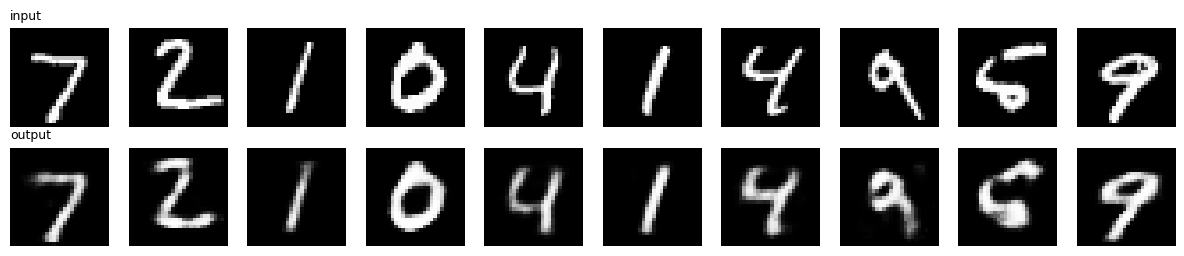

In [5]:
def mse_per_image(a, b):
    return np.mean((a - b) ** 2, axis=1)

rec_test = ae.predict(x_test_flat, verbose=0)
err_ae = mse_per_image(x_test_flat, rec_test)
print(f"dense AE, code 32: mean squared error per pixel on the test set = {err_ae.mean():.4f}")

def show_pairs(top, bottom, n=10, titles=("input", "output"), figsize=(12, 2.6)):
    plt.figure(figsize=figsize)
    for i in range(n):
        for row, imgs in enumerate((top, bottom)):
            ax = plt.subplot(2, n, row * n + i + 1)
            ax.imshow(imgs[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
            ax.axis("off")
            if i == 0:
                ax.set_title(titles[row], fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

show_pairs(x_test_flat, rec_test)

### Why we see this

The digits come back recognisable but **soft at the edges**. Where the model is unsure exactly how thick a
stroke is, or where it ends, the loss is smallest if it outputs the *average* of the possibilities, and an
average of several sharp strokes is one blurry stroke. Blur is the autoencoder hedging its bets.

---
## Step 6 - The honest baseline: PCA with 32 components

PCA finds the 32 straight directions in pixel space that keep the most variance. A **linear** autoencoder
trained with squared error learns the same 32-dimensional subspace. Our autoencoder has ReLUs, so it can bend.

> **Predict:** will the non-linear autoencoder beat PCA at the same 32 numbers? By a little or a lot?

test MSE per pixel   PCA, 32 numbers: 0.0153
test MSE per pixel   dense AE, 32   : 0.0123


  PCA k =   2: MSE 0.0555
  PCA k =   4: MSE 0.0474
  PCA k =   8: MSE 0.0365
  PCA k =  16: MSE 0.0254
  PCA k =  32: MSE 0.0153
  PCA k =  64: MSE 0.0078
  PCA k = 128: MSE 0.0034
  PCA k = 256: MSE 0.0011


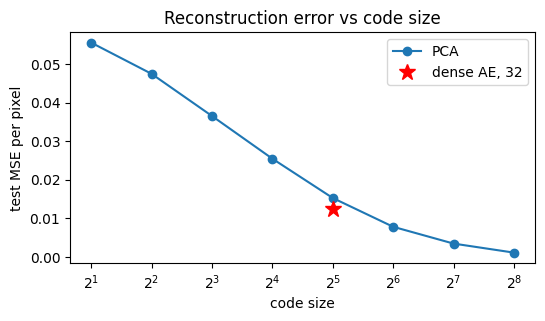

In [6]:
mean_img = x_train_flat.mean(axis=0)
_, svals, Vt = np.linalg.svd(x_train_flat - mean_img, full_matrices=False)

def pca_reconstruct(x, k):
    z = (x - mean_img) @ Vt[:k].T          # encode: k numbers per image
    return np.clip(z @ Vt[:k] + mean_img, 0, 1)

err_pca32 = mse_per_image(x_test_flat, pca_reconstruct(x_test_flat, 32))
print(f"test MSE per pixel   PCA, 32 numbers: {err_pca32.mean():.4f}")
print(f"test MSE per pixel   dense AE, 32   : {err_ae.mean():.4f}")

ks = [2, 4, 8, 16, 32, 64, 128, 256]
pca_curve = [mse_per_image(x_test_flat, pca_reconstruct(x_test_flat, k)).mean() for k in ks]
for k, e in zip(ks, pca_curve):
    print(f"  PCA k = {k:3d}: MSE {e:.4f}")
plt.figure(figsize=(6, 3))
plt.plot(ks, pca_curve, "o-", label="PCA")
plt.plot([32], [err_ae.mean()], "r*", ms=12, label="dense AE, 32")
plt.xscale("log", base=2); plt.xlabel("code size"); plt.ylabel("test MSE per pixel")
plt.title("Reconstruction error vs code size"); plt.legend(); plt.show()

### Why we see this

The autoencoder wins, but not by a landslide: roughly a fifth less error than PCA at 32 numbers, after
eight short epochs. PCA's answer took one matrix factorisation and has nothing to tune. The curve shows the
shape that matters for choosing a code size: error falls quickly for the first few dimensions and then
flattens, so beyond a point extra numbers buy little. If PCA does as well as your autoencoder on your data,
use PCA.

---
## Step 7 - A 2-number code you can draw

Squeeze every digit through **2** numbers, so each digit becomes a point on a page. Then colour the points by
their true label, which the autoencoder never saw.

> **Predict:** will digits of the same class land near each other? Will the points fill the page evenly?

2-D autoencoder trained in 7s


test MSE with 2 numbers:  AE 0.0470   PCA 0.0555


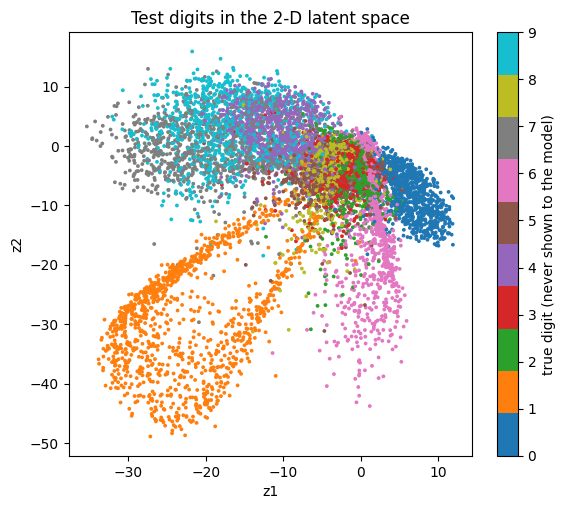

In [7]:
# a linear code layer: ReLU on a 2-number code would waste three quarters of the page
ae2, enc2 = dense_autoencoder(code_size=2, name="ae2", code_act=None)
ae2.compile(optimizer="adam", loss="binary_crossentropy")
t = time.time()
ae2.fit(x_train_flat, x_train_flat, epochs=12, batch_size=128, verbose=0)
print(f"2-D autoencoder trained in {time.time() - t:.0f}s")
z_test = enc2.predict(x_test_flat, verbose=0)
err_ae2 = mse_per_image(x_test_flat, ae2.predict(x_test_flat, verbose=0)).mean()
err_pca2 = mse_per_image(x_test_flat, pca_reconstruct(x_test_flat, 2)).mean()
print(f"test MSE with 2 numbers:  AE {err_ae2:.4f}   PCA {err_pca2:.4f}")

plt.figure(figsize=(6.5, 5.5))
sc = plt.scatter(z_test[:, 0], z_test[:, 1], c=y_test, cmap="tab10", s=3)
plt.colorbar(sc, ticks=range(10), label="true digit (never shown to the model)")
plt.title("Test digits in the 2-D latent space"); plt.xlabel("z1"); plt.ylabel("z2"); plt.show()

### Why we see this

Classes form clusters, because similar-looking digits need similar codes to be rebuilt well. But the clusters
are oddly shaped (long streaks and wedges), of very different sizes, and separated by **empty space**. Nothing
in the loss asked the codes to be round, evenly spread or gap-free: it only asked that each code decode back
to its own digit.

---
## Step 8 - Decode points nobody used: the holes

Take a 20 × 20 grid of cells over the box that contains the codes, and count how many cells contain no test
code at all. Then decode random points from that box and look at them.

> **Predict:** what fraction of the box is empty? What will a random point decode to?

cells of a 20 x 20 grid over the latent box with no test code in them: 30%
distance from each random point to the nearest real code: [0.42 0.1  5.25 1.05 0.08 0.16 8.35 0.49 0.31 0.45]
typical distance between a real code and its nearest neighbour: 0.254


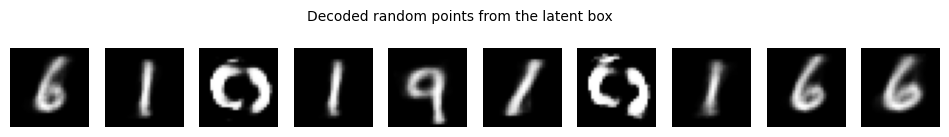

In [8]:
lo, hi = z_test.min(axis=0), z_test.max(axis=0)
H, _, _ = np.histogram2d(z_test[:, 0], z_test[:, 1], bins=20, range=[[lo[0], hi[0]], [lo[1], hi[1]]])
print(f"cells of a 20 x 20 grid over the latent box with no test code in them: {np.mean(H == 0):.0%}")

rng = np.random.default_rng(27)
z_rand = rng.uniform(lo, hi, size=(10, 2))
decoder_in = layers.Input(shape=(2,))
h = ae2.get_layer("dec_128")(decoder_in)
decoder2 = keras.Model(decoder_in, ae2.get_layer("out_784")(h))
dec_rand = decoder2.predict(z_rand, verbose=0)

# how far is each random point from the nearest real code, compared with typical neighbour spacing?
d_rand = np.min(np.linalg.norm(z_test[None, :, :] - z_rand[:, None, :], axis=2), axis=1)
sub = z_test[:2000]
dd = np.linalg.norm(sub[None] - sub[:, None], axis=2); np.fill_diagonal(dd, np.inf)
print("distance from each random point to the nearest real code:", np.round(d_rand, 2))
print(f"typical distance between a real code and its nearest neighbour: {np.median(dd.min(axis=1)):.3f}")

plt.figure(figsize=(12, 1.6))
for i in range(10):
    ax = plt.subplot(1, 10, i + 1); ax.imshow(dec_rand[i].reshape(28, 28), cmap="gray"); ax.axis("off")
plt.suptitle("Decoded random points from the latent box", fontsize=10); plt.show()

### Why we see this

A large share of the box is empty, and random points usually land in it, far from any real code. The decoder
was never trained there, so what it produces is a smear, a blend of two digits or a confident-looking digit
that changes abruptly a short step away. **A plain autoencoder is a good compressor and a poor generator.**
Making the space gap-free, so that any point decodes to something sensible, is exactly the job of the
variational autoencoder in Chapter 28.

---
## Step 9 - A denoising autoencoder

Corrupt the input with noise, but keep the **clean** digit as the target: `fit(noisy, clean)`. Now copying is
useless: the network must learn what digits look like, so it can put back what the noise destroyed.

> **Predict:** on noisy test digits, which does better: the plain autoencoder from Step 4, or the denoiser?

denoiser trained in 5s


MSE vs clean:  noisy input itself 0.1157
               plain AE on noisy  0.0663
               denoising AE       0.0258


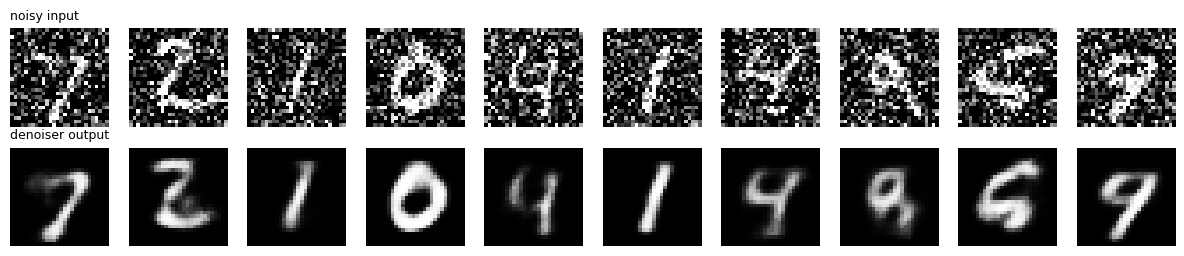

In [9]:
NOISE = 0.5
def add_noise(x, seed):
    r = np.random.default_rng(seed)
    return np.clip(x + NOISE * r.normal(size=x.shape), 0, 1).astype("float32")

x_train_noisy = add_noise(x_train_flat, 1)
x_test_noisy = add_noise(x_test_flat, 2)

dae, _ = dense_autoencoder(name="denoiser")
dae.compile(optimizer="adam", loss="binary_crossentropy")
t = time.time()
dae.fit(x_train_noisy, x_train_flat, epochs=8, batch_size=128, verbose=0)
print(f"denoiser trained in {time.time() - t:.0f}s")

out_plain = ae.predict(x_test_noisy, verbose=0)
out_dae = dae.predict(x_test_noisy, verbose=0)
print(f"MSE vs clean:  noisy input itself {mse_per_image(x_test_noisy, x_test_flat).mean():.4f}")
print(f"               plain AE on noisy  {mse_per_image(out_plain, x_test_flat).mean():.4f}")
print(f"               denoising AE       {mse_per_image(out_dae, x_test_flat).mean():.4f}")
show_pairs(x_test_noisy, out_dae, titles=("noisy input", "denoiser output"))

### Why we see this

The denoiser wins clearly. The plain autoencoder was trained only on clean digits, so noise is something it has
never seen, and some of it leaks through. The denoiser has learnt, in effect, "the nearest clean digit to this
mess". This idea, *corrupt, then learn to undo the corruption*, scaled up to many noise levels, is the training
objective of diffusion models (Chapter 29).

---
## Step 10 - A convolutional autoencoder: 28 → 14 → 7 → 14 → 28

Strided convolutions halve the picture on the way down; transposed convolutions (Chapter 15) double it on the
way up. With `padding='same'` and stride 2 the rule is simple: down, out = in / 2 rounded up; up, out = in × 2.

> **Predict, before running:** the output shape and parameter count of every layer. Use
> (3 · 3 · C_in + 1) · C_out for each convolution, transposed or not. Then: how many numbers are in the code?

In [10]:
x_train_img = x_train[..., None]
x_test_img = x_test[..., None]

conv_hand = [
    ("Conv2D 16, s2",          (14, 14, 16), (9 * 1 + 1) * 16),
    ("Conv2D 4, s2  (code)",   (7, 7, 4),    (9 * 16 + 1) * 4),
    ("Conv2DTranspose 16, s2", (14, 14, 16), (9 * 4 + 1) * 16),
    ("Conv2DTranspose 16, s2", (28, 28, 16), (9 * 16 + 1) * 16),
    ("Conv2D 1, sigmoid",      (28, 28, 1),  (9 * 16 + 1) * 1),
]
for name, shape, p in conv_hand:
    print(f"{name:24s} {str(shape):14s} {p:>6,}")
CONV_TOTAL = sum(p for *_, p in conv_hand)
print(f"{'total':24s} {'':14s} {CONV_TOTAL:>6,}   code = 7*7*4 = {7*7*4} numbers")

inp = layers.Input(shape=(28, 28, 1))
h = layers.Conv2D(16, 3, strides=2, padding="same", activation="relu")(inp)
code = layers.Conv2D(4, 3, strides=2, padding="same", activation="relu")(h)
h = layers.Conv2DTranspose(16, 3, strides=2, padding="same", activation="relu")(code)
h = layers.Conv2DTranspose(16, 3, strides=2, padding="same", activation="relu")(h)
out = layers.Conv2D(1, 3, padding="same", activation="sigmoid")(h)
cae = keras.Model(inp, out, name="conv_ae")
cae.summary()
assert cae.count_params() == CONV_TOTAL
for lyr, (_, shape, _) in zip(cae.layers[1:], conv_hand):
    assert tuple(lyr.output.shape[1:]) == shape, (lyr.name, lyr.output.shape)
print("shapes and parameter count match the hand table")

Conv2D 16, s2            (14, 14, 16)      160
Conv2D 4, s2  (code)     (7, 7, 4)         580
Conv2DTranspose 16, s2   (14, 14, 16)      592
Conv2DTranspose 16, s2   (28, 28, 16)    2,320
Conv2D 1, sigmoid        (28, 28, 1)       145
total                                    3,797   code = 7*7*4 = 196 numbers


Model: "conv_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 14, 14, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 4)        │           580 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 16)     │           592 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 16)     │         2,320 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 1)      │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,797 (14.83 KB)

 Trainable params: 3,797 (14.83 KB)

 Non-trainable params: 0 (0.00 B)

shapes and parameter count match the hand table


Now train it and compare with the dense autoencoder. It has far fewer parameters, but its code is bigger
(196 numbers against 32): keep that in mind before declaring a winner.

> **Predict:** lower or higher test error than the dense autoencoder?

Epoch 1/5


157/157 - 3s - 17ms/step - loss: 0.3216


Epoch 2/5


157/157 - 1s - 9ms/step - loss: 0.1000


Epoch 3/5


157/157 - 2s - 11ms/step - loss: 0.0788


... (2 outputs left out)

Epoch 5/5


157/157 - 1s - 9ms/step - loss: 0.0708


conv AE trained in 9s


test MSE per pixel: conv AE (3,797 params, code 196) 0.0030
                    dense AE (209,968 params, code 32)  0.0123
                    PCA with 196 numbers                0.0018


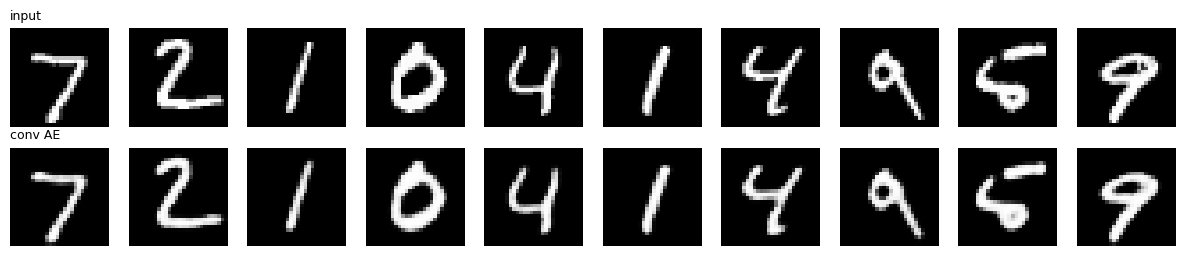

In [11]:
cae.compile(optimizer="adam", loss="binary_crossentropy")
t = time.time()
cae.fit(x_train_img, x_train_img, epochs=5, batch_size=128, verbose=2)
print(f"conv AE trained in {time.time() - t:.0f}s")
rec_cae = cae.predict(x_test_img, verbose=0).reshape(-1, 784)
err_cae = mse_per_image(x_test_flat, rec_cae)
print(f"test MSE per pixel: conv AE ({cae.count_params():,} params, code 196) {err_cae.mean():.4f}")
print(f"                    dense AE ({ae.count_params():,} params, code 32)  {err_ae.mean():.4f}")
err_pca196 = mse_per_image(x_test_flat, pca_reconstruct(x_test_flat, 196)).mean()
print(f"                    PCA with 196 numbers                {err_pca196:.4f}")
show_pairs(x_test_flat, rec_cae, titles=("input", "conv AE"))

### Why we see this

The convolutional autoencoder has under 2% of the dense model's parameters, because each filter is reused at
every position (Chapter 14), and its error is far lower. But its code is six times bigger, which makes
reconstruction much easier, and the fair comparison, PCA with the same 196 numbers, does better still after
only five epochs. Compare at equal code size, against PCA, or the comparison means little.

---
## Step 11 - Anomaly detection: train without one digit

Train a fresh dense autoencoder on every digit **except 2**. Then measure the reconstruction error of every
test digit. The threshold is chosen on held-out **normal** digits only (the 99th percentile of their errors):
you never get to look at the anomalies when you set it.

> **Predict:** what share of the 2s will be flagged? What share of normal digits will be falsely flagged?

held out digit 2: threshold 0.0407
   anomalies flagged (recall)      : 15.8%
   normal digits falsely flagged   : 0.6%
   median error  normal 0.0139   held-out 0.0305
   with a looser threshold (95th pct): flagged 51.8%, false alarms 4.2%
   AUC = 0.913   (0.5 = no better than a coin, 1.0 = perfect ranking)
(4s)


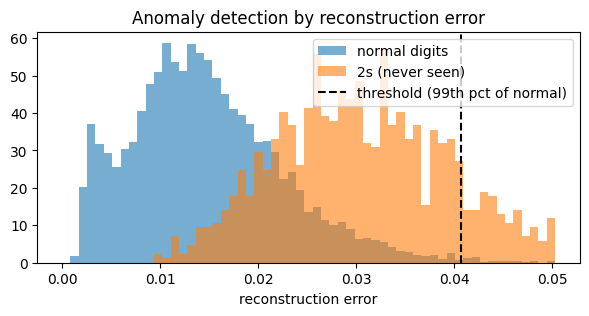

In [12]:
def anomaly_experiment(held_out, epochs=6):
    keep = y_train != held_out
    model, _ = dense_autoencoder(name=f"ae_no_{held_out}")
    model.compile(optimizer="adam", loss="binary_crossentropy")
    x_norm = x_train_flat[keep]
    n_val = 2000                                # last 2,000 normal digits: threshold only
    model.fit(x_norm[:-n_val], x_norm[:-n_val], epochs=epochs, batch_size=128, verbose=0)
    val_err = mse_per_image(x_norm[-n_val:], model.predict(x_norm[-n_val:], verbose=0))
    thr = np.percentile(val_err, 99)
    err = mse_per_image(x_test_flat, model.predict(x_test_flat, verbose=0))
    is_anom = y_test == held_out
    print(f"held out digit {held_out}: threshold {thr:.4f}")
    print(f"   anomalies flagged (recall)      : {np.mean(err[is_anom] > thr):.1%}")
    print(f"   normal digits falsely flagged   : {np.mean(err[~is_anom] > thr):.1%}")
    print(f"   median error  normal {np.median(err[~is_anom]):.4f}   held-out {np.median(err[is_anom]):.4f}")
    thr95 = np.percentile(val_err, 95)
    print(f"   with a looser threshold (95th pct): flagged {np.mean(err[is_anom] > thr95):.1%},"
          f" false alarms {np.mean(err[~is_anom] > thr95):.1%}")
    # AUC: the chance that a random anomaly has a higher error than a random normal digit
    ranks = err.argsort().argsort() + 1
    n_a, n_n = is_anom.sum(), (~is_anom).sum()
    auc = (ranks[is_anom].sum() - n_a * (n_a + 1) / 2) / (n_a * n_n)
    print(f"   AUC = {auc:.3f}   (0.5 = no better than a coin, 1.0 = perfect ranking)")
    return err, is_anom, thr

t = time.time()
err2, anom2, thr2 = anomaly_experiment(2)
print(f"({time.time() - t:.0f}s)")
plt.figure(figsize=(7, 3))
bins = np.linspace(0, np.percentile(err2, 99.5), 60)
plt.hist(err2[~anom2], bins=bins, alpha=0.6, density=True, label="normal digits")
plt.hist(err2[anom2], bins=bins, alpha=0.6, density=True, label="2s (never seen)")
plt.axvline(thr2, color="k", ls="--", label="threshold (99th pct of normal)")
plt.xlabel("reconstruction error"); plt.legend(); plt.title("Anomaly detection by reconstruction error"); plt.show()

### Why we see this

The typical 2 has about twice the error of a typical normal digit, and the AUC says a random 2 usually ranks
above a random normal digit. Yet at a strict threshold (about 1 false alarm in 100) only a small share of the
2s is caught, because the histograms **overlap** heavily: normal digits have a long tail of hard, scruffy
examples. Loosening the threshold catches more 2s and raises more false alarms; no threshold removes both.
The threshold is a business decision (what does a false alarm cost, what does a miss cost?), not a property
of the model.

---
## Step 12 - The failure mode: an anomaly that is easy to draw

Repeat the experiment, holding out the digit **1** instead.

> **Predict:** better or worse detection than for the 2s? Think about how much ink a 1 has.

held out digit 1: threshold 0.0417
   anomalies flagged (recall)      : 0.0%
   normal digits falsely flagged   : 0.7%
   median error  normal 0.0166   held-out 0.0152
   with a looser threshold (95th pct): flagged 0.1%, false alarms 3.9%
   AUC = 0.408   (0.5 = no better than a coin, 1.0 = perfect ranking)
(4s)


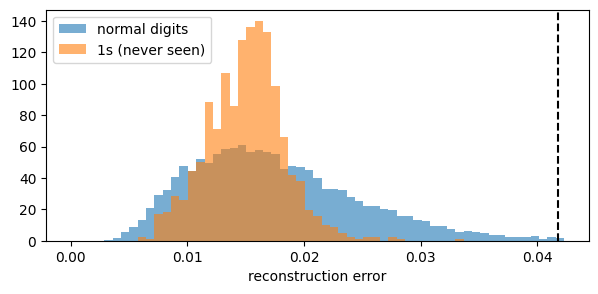

In [13]:
t = time.time()
err1, anom1, thr1 = anomaly_experiment(1)
print(f"({time.time() - t:.0f}s)")
plt.figure(figsize=(7, 3))
bins = np.linspace(0, np.percentile(err1, 99.5), 60)
plt.hist(err1[~anom1], bins=bins, alpha=0.6, density=True, label="normal digits")
plt.hist(err1[anom1], bins=bins, alpha=0.6, density=True, label="1s (never seen)")
plt.axvline(thr1, color="k", ls="--"); plt.xlabel("reconstruction error"); plt.legend(); plt.show()

### Why we see this

The unseen 1s get **lower** errors than the typical normal digit, and the AUC falls below 0.5: the detector
ranks them as *more* normal than the digits it was trained on. A 1 is a single short stroke with little ink, and
an autoencoder that can draw strokes can draw it, seen or not. Reconstruction error measures "is this hard to
rebuild", not "is this unusual". Anomalies that are *simpler* than normal data slip straight through: always
test an anomaly detector on the kinds of anomaly you actually expect.

---
## Step 13 - The identity cheat: a middle that is too wide

Build autoencoders whose middle is **wider** than the input (784 → 1024 → 784): one with ReLU and sigmoid like
the others, and one with no activations at all, trained with squared error. Train both on digits. Then hand
every model the **noisy** digits of Step 9 and measure what share of the added noise comes out the other end.
A model that rebuilds digits should pass little noise; a model that copies pixels should pass most of it.

> **Predict:** rank the three models (narrow 32, wide ReLU, wide linear) by clean-digit error, then by the
> share of noise they pass through.

wide AE parameters: 1,607,440


narrow (32)  clean-digit MSE 0.0123   share of the added noise that comes out the other end: 15%


wide (1024)  clean-digit MSE 0.0023   share of the added noise that comes out the other end: 13%


wide linear  clean-digit MSE 0.0004   share of the added noise that comes out the other end: 65%


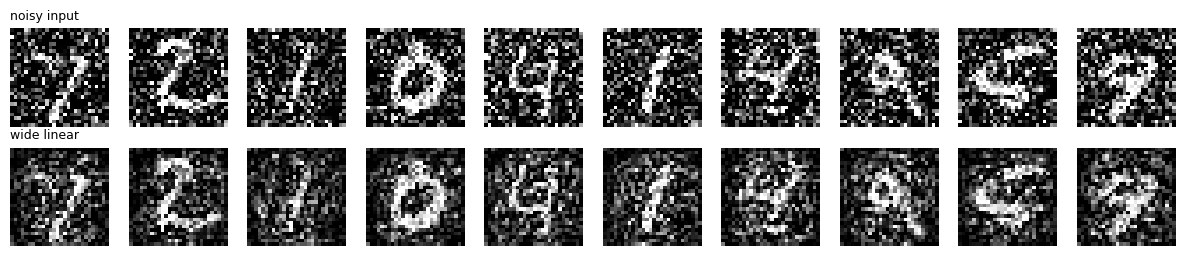

In [14]:
inp = layers.Input(shape=(784,))
wide = keras.Model(inp, layers.Dense(784, activation="sigmoid")(layers.Dense(1024, activation="relu")(inp)), name="wide")
wide.compile(optimizer="adam", loss="binary_crossentropy")
wide.fit(x_train_flat, x_train_flat, epochs=5, batch_size=128, verbose=0)
print("wide AE parameters:", f"{wide.count_params():,}")
assert wide.count_params() == (784 + 1) * 1024 + (1024 + 1) * 784

# the same width with no activations at all, trained with squared error: the textbook copier
inp = layers.Input(shape=(784,))
wide_lin = keras.Model(inp, layers.Dense(784)(layers.Dense(1024)(inp)), name="wide_linear")
wide_lin.compile(optimizer="adam", loss="mse")
wide_lin.fit(x_train_flat, x_train_flat, epochs=5, batch_size=128, verbose=0)

d_in = x_test_noisy - x_test_flat                      # the noise we added
for name, m in [("narrow (32)", ae), ("wide (1024)", wide), ("wide linear", wide_lin)]:
    out_clean = m.predict(x_test_flat, verbose=0)
    out_noisy = m.predict(x_test_noisy, verbose=0)
    d_out = out_noisy - out_clean                     # what the noise changed at the output
    passed = np.sum(d_out * d_in) / np.sum(d_in * d_in)
    print(f"{name:12s} clean-digit MSE {mse_per_image(x_test_flat, out_clean).mean():.4f}   "
          f"share of the added noise that comes out the other end: {passed:.0%}")
show_pairs(x_test_noisy, wide_lin.predict(x_test_noisy, verbose=0), titles=("noisy input", "wide linear"))

### Why we see this

The wide **linear** model has by far the lowest error of the lab, and it passes about two thirds of the noise
straight through: it has learnt something close to "copy every pixel", which scores beautifully and knows
nothing about digits. The narrow model passes little noise, because 32 numbers cannot carry it.

The surprise is the wide **ReLU** model: in five epochs it did *not* become a copier; it passes no more noise
than the narrow one. A wide middle *allows* the identity; it does not guarantee it, and what training finds
depends on the activations, the loss and how long you train. That is exactly why you test for copying instead
of assuming. And even when it does not copy, a 1,024-number code is bigger than the 784-pixel input: useless
as compression or as a map. **Low reconstruction error is not the goal; the bottleneck is.**

In [15]:
print(f"Total lab time: {time.time() - T0:.0f}s")

Total lab time: 72s


---
## Trials: change one thing at a time

Change one setting, **write your prediction first**, rerun the steps named, and fill in the last column.

| # | Change | Rerun | Predict | Observe |
|---|---|---|---|---|
| 1 | Code size 32 → 8, then → 128 (Step 3) | 3 to 6 | Error up or down? Parameter count? | |
| 2 | Loss `binary_crossentropy` → `mse` | 4, 5 | Sharper or blurrier? Does the loss number mean the same? | |
| 3 | Remove the `/ 255.0` scaling | 2 to 5 | What can a sigmoid output do with targets up to 255? | |
| 4 | `NOISE = 0.5` → 0.2, then → 0.8 | 9 | Where does the denoiser start to invent digits? | |
| 5 | Conv code channels 4 → 16 | 10 | Code size? Error? Is it still a bottleneck? | |
| 6 | Hold out 7, then 0, in Step 11 | 11 | Which is easier to catch, and why? | |
| 7 | Threshold at the 90th percentile instead of the 99th | 11 | Recall and false-alarm rate both move: by how much? | |
| 8 | `N_TRAIN` 20,000 → 60,000 and epochs ×3 | 4 to 8 | Does the 2-D map get fewer holes, or only tighter clusters? | |
| 9 | Train the wide ReLU model for 30 epochs | 13 | Does its noise pass-through creep up towards the linear one's? | |

## Exercises

1. **Linear autoencoder.** Remove every activation from the 32-number model (use `activation=None` and a
   linear output) and train it with `mse`. Compare its test error with PCA at 32. How close do they get?
2. **Latent walk.** Encode a test 3 and a test 8 with the 2-D model, decode ten points on the straight line
   between their codes, and plot them. Where does the walk pass through a hole?
3. **Sparse autoencoder.** Make the code 256 wide (overcomplete) and add
   `activity_regularizer=keras.regularizers.l1(1e-5)` to the code layer. How many code units are non-zero for
   a typical digit? Compare with the same model without the penalty.
4. **Features for free.** Train a logistic regression (one `Dense(10, softmax)`) on the 32-number codes of
   only 1,000 labelled digits, then on the raw pixels of the same 1,000. Which wins on the test set?
5. **UpSampling instead of transposed.** Replace each `Conv2DTranspose` with `UpSampling2D(2)` followed by
   `Conv2D(16, 3, padding='same')`. Predict the new parameter count first, then compare the reconstructions.
6. **Fashion-MNIST.** Swap the dataset for `keras.datasets.fashion_mnist`. Which classes reconstruct worst,
   and what do they have in common?

## Cheat sheet

| Idea | One line |
|---|---|
| Autoencoder | `fit(x, x)`: encoder → narrow code → decoder; no labels needed |
| Dense param count | (in + 1) × units per layer; 784-128-32-128-784 = 209,968 |
| Output layer | sigmoid for pixels in [0, 1], with BCE or MSE; linear for unbounded data, with MSE |
| Blur | the loss rewards the average of possible outputs |
| PCA | a linear AE with MSE learns PCA's subspace; always compare with it |
| 2-D latent | clusters with holes; random points decode to junk (the VAE fixes this) |
| Denoising | `fit(noisy, clean)`: learns structure, not copying |
| Conv AE | stride-2 Conv down, `Conv2DTranspose` up; 28 → 14 → 7 → 14 → 28 |
| Anomaly detection | threshold on normal validation errors; simple anomalies can slip through |
| Wide middle | can learn to copy; check it on noise |